**Aim:** Integrate differential expressed genes (DEGs) from different comparisons.
**Tools**
- `limma` – gene level 
- `iPAGE` – pathway level

In [1]:
import pandas as pd 
from utils import find_top

from matplotlib import pyplot as plt
from venn import venn 

In [2]:
def read_diffexp_table(name):
    d = {
        'MethvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MethvsSaline.txt',  sep='\t'),
        'MDMAvsSaline':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsSaline.txt',sep='\t'),
        'MDMAvsMeth':pd.read_csv(
            f'diffexp/{name}/delta_exp_MDMAvsMeth.txt',  sep='\t')
    }

    out = pd.concat(d.values(), axis=1, keys=d.keys())
    out.index = out.index.str.upper()
    return out

## overlapping analysis

___
- generate similar diagram for MDMAvsMeth_up and SalinevsMeth_up
- look whether any of the 321 genes from the yellow circle in all_neurons overlap with any of the gens from the above analysis


___
We’re interested in genes which are higher in saline and lower in meth and the overlapping ones with MDMAvsMeth_up. 
However, you previously plotted MethvsSaline_up and overlapped it with MDMAvsMeth_up. If it is easier you could plot Meth vs Saline down as it should be similar to Saline vs Meth up. 


___
<!-- ___
>@ Abe: do you think you can generate a list with MDMA vs Meth up overlapped with Saline vs Meth up? It may not be any different but perhaps there’ll be some other hits that may turn out to be interesting?
 -->
Wed Nov  9 11:34:14 PST 2022
 
- Saba: annotate the 102 genes MDMAvsSaline_up & MDMAvsMeth_up with names and function (focus on neuronal genes, no need to annotate ubiquitously expressed genes such as actin, tubulin)
- Abe: bring analysis up to date and run DE analysis MDMAvsMeth, MDMAvsSaline, MethvsSaline. Run GO analysis.


In [36]:
fc_thr = 0.2
pv_thr = 0.05


diffexp = {}

for cond in ['all_neurons',
             'Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    diffexp[cond] = {}
    for comp in ['MethvsSaline','MDMAvsMeth','MDMAvsSaline']:
        print(comp)
        up,down = find_top(
            read_diffexp_table(cond)[comp],
            'log2FoldChange',fc_thr,'pvalue',pv_thr
        )
        diffexp[cond][f'{comp}_up'] = set(up.index)
        diffexp[cond][f'{comp}_down'] = set(down.index)
    print(20*'__')

all_neurons
MethvsSaline
up:  3138
down: 1404
MDMAvsMeth
up:  474
down: 927
MDMAvsSaline
up:  2923
down: 1623
________________________________________
Astrocytes
MethvsSaline
up:  87
down: 547
MDMAvsMeth
up:  306
down: 112
MDMAvsSaline
up:  166
down: 460
________________________________________
Endothelial
MethvsSaline
up:  254
down: 598
MDMAvsMeth
up:  78
down: 895
MDMAvsSaline
up:  109
down: 1258
________________________________________
Microglia
MethvsSaline
up:  101
down: 964
MDMAvsMeth
up:  39
down: 959
MDMAvsSaline
up:  19
down: 1789
________________________________________
Oligodendrocytes
MethvsSaline
up:  812
down: 643
MDMAvsMeth
up:  174
down: 436
MDMAvsSaline
up:  649
down: 649
________________________________________


> - Meth & MDMA high and saline low
> - MDMA & saline high and Meth low


In [37]:
cmaps = ["cool", list("rgb"), "plasma", "viridis", "Set1"]

In [51]:
# fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(40, 20))

# for cond,ax in zip(
#     ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
#     axes[0,[0,1,2,3,4]]):
#     venn({comp: diffexp[cond][comp] for comp in ['MethvsSaline_up','MDMAvsSaline_up',
#                                                 'MethvsSaline_down','MDMAvsSaline_down']},
#          ax=ax,legend_loc="lower right",fontsize=12,cmap=cmaps[0])
#     ax.set_title(cond,fontsize=20)

# for cond,ax in zip(
#     ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes'],
#     axes[1,[0,1,2,3,4]]):
#     venn({comp: diffexp[cond][comp] for comp in ['MDMAvsMeth_up','MDMAvsSaline_down',
#                                                  'MDMAvsMeth_down','MDMAvsSaline_up'
#                                                 ]},
#          ax=ax,legend_loc="lower right",fontsize=12,cmap=cmaps[2])
#     # ax.set_title(cond,fontsize=20)
# fig.savefig('diffexp/venn_full.pdf')
# plt.show()

___

In [49]:
def plot_overlaps(A,B,C,D,save=False,fontsize=8):
    
    fig, axes = plt.subplots(ncols=5, nrows=2, figsize=(12, 5))
    
    cell_types = ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']

    for cond,ax,l in zip(cell_types, axes[0,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
        venn({comp: diffexp[cond][comp] for comp in [C,D]},
             ax=ax,legend_loc=l,fontsize=fontsize,cmap=cmaps[0])
        ax.set_title(cond,fontsize=10)

    for cond,ax,l in zip(cell_types,axes[1,[0,1,2,3,4]],[None,None,None,None,"lower right"]):
        venn({comp: diffexp[cond][comp] for comp in [A,B,C]},
             ax=ax,legend_loc=l,fontsize=fontsize,cmap=cmaps[1])
        ax.set_title(cond,fontsize=10)

    if save:
        fig.savefig(f'diffexp/{save}.pdf')
    plt.show()

## MDMA vs Sal (up) & MDMA vs Meth (up): 
- MDMA-prosocial effect 
- Common genes are MDMA prosocial


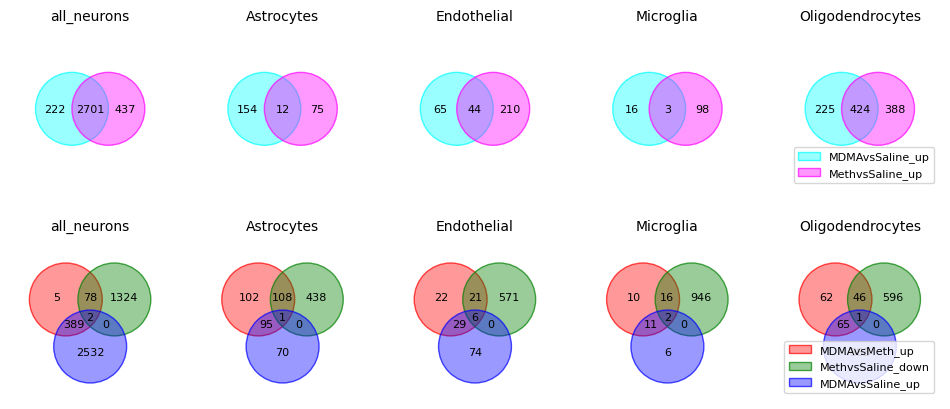

In [75]:
plot_overlaps(
    'MDMAvsMeth_up','MethvsSaline_down','MDMAvsSaline_up', 'MethvsSaline_up',
    save = 'venn-up'
)

In [63]:
overlaps = {}

for cond in ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    A,B,C = ['MDMAvsMeth_up','MethvsSaline_down','MDMAvsSaline_up']
    a,b,c = [diffexp[cond][comp] for comp in [A,B,C]]

    overlaps[cond] = pd.concat({
        ## group 1
        f"{A}-{B}-{C}":pd.DataFrame({'genes':[gene for gene in a - b - c]}).set_index('genes'),
        ## group 2
        f"({A}&{B})-{C}":pd.DataFrame({'genes':[gene for gene in (a & b) - c]}).set_index('genes'),
        ## group 3
        f"({A}&{C})-{B}":pd.DataFrame({"genes":[gene for gene in (a & c) - b]}).set_index('genes'),
        ## group 4
        f"{A}&{B}&{C}":pd.DataFrame({"genes":[gene for gene in (a & b & c)]}).set_index('genes')
    })

all_neurons
Astrocytes
Endothelial
Microglia
Oligodendrocytes


In [64]:
pd.concat(overlaps).to_csv('diffexp/venn-up.csv')

In [65]:
pd.concat(overlaps).to_excel('diffexp/venn-up.xlsx')

___

## MDMA vs Sal (down) VS MDMA vs Meth (down): 
- MDMA-prosocial effect 
- Consider refining by excluding genes that are up Meth vs Sal

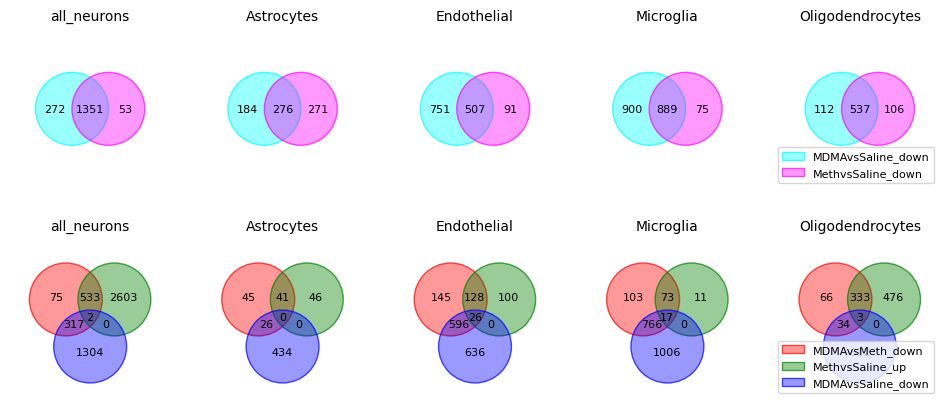

In [74]:
plot_overlaps(
    'MDMAvsMeth_down','MethvsSaline_up','MDMAvsSaline_down', 'MethvsSaline_down',
    save = 'venn-down'
)

In [67]:
overlaps = {}
for cond in ['all_neurons','Astrocytes', 'Endothelial', 'Microglia', 'Oligodendrocytes']:
    print(cond)
    A,B,C = ['MDMAvsMeth_down','MethvsSaline_up','MDMAvsSaline_down']
    a,b,c = [diffexp[cond][comp] for comp in [A,B,C]]

    overlaps[cond] = pd.concat({
        ## group 1
        f"{A}-{B}-{C}":pd.DataFrame({'genes':[gene for gene in a - b - c]}).set_index('genes'),
        # ## group 2
        # f"({A}&{B})-{C}":pd.DataFrame({'genes':[gene for gene in (a & b) - c]}).set_index('genes'),
        # ## group 3
        # f"({A}&{C})-{B}":pd.DataFrame({"genes":[gene for gene in (a & c) - b]}).set_index('genes'),
        # ## group 4
        # f"{A}&{B}&{C}":pd.DataFrame({"genes":[gene for gene in (a & b & c)]}).set_index('genes')
    })

all_neurons
Astrocytes
Endothelial
Microglia
Oligodendrocytes


In [71]:
pd.concat(overlaps).to_csv('diffexp/venn-down.csv')

In [72]:
pd.concat(overlaps).to_excel('diffexp/venn-down.xlsx')

___

#

In [13]:
!date

Wed Nov  9 21:57:01 PST 2022
